In [1]:
import pandas as pd
import numpy as np

In [2]:
import re
import nltk

In [3]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

In [6]:
from sklearn.ensemble import VotingClassifier

In [7]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
import joblib

In [10]:
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [11]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

In [12]:
df = pd.read_csv("../data/sentiment_dataset.csv")

df.head()

,text,selected_text,sentiment
0,Quick post about the order during my break; su...,superb quality,positive
1,Back with a note about the meeting over the we...,amazing result,positive
2,Back with a note about the headphones this aft...,dreadful experience,negative
3,Back with a note about the charger after the c...,included in the report,neutral
4,Finally checked the order last night; included...,included in the report,neutral


In [13]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

Dataset Shape: (27481, 3)

Columns:
Index(['text', 'selected_text', 'sentiment'], dtype='str')

Missing Values:
text             0
selected_text    0
sentiment        0
dtype: int64

Sentiment Distribution:
sentiment
neutral     11118
positive     8582
negative     7781
Name: count, dtype: int64


In [14]:
df = df.dropna(
    subset=["text", "sentiment"]
)

df = df.reset_index(drop=True)

print(df.isnull().sum())

text             0
selected_text    0
sentiment        0
dtype: int64


In [15]:
df = df.drop_duplicates(
    subset=["text"]
)

df = df.reset_index(drop=True)

print("Dataset Shape:", df.shape)

Dataset Shape: (27481, 3)


In [16]:
def clean_text(text):

    # Convert to string
    text = str(text)

    # Remove URLs
    text = re.sub(
        r"http\S+|www\S+|https\S+",
        "",
        text
    )

    # Remove mentions
    text = re.sub(
        r"@\w+",
        "",
        text
    )

    # Remove hashtag symbol
    text = re.sub(
        r"#",
        "",
        text
    )

    # Convert to lowercase
    text = text.lower()

    # Remove special characters and numbers
    text = re.sub(
        r"[^a-zA-Z\s]",
        "",
        text
    )

    # Tokenization
    tokens = word_tokenize(text)

    # Remove stopwords
    tokens = [
        word
        for word in tokens
        if word not in stop_words
    ]

    # Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    # Join tokens
    return " ".join(tokens)

In [17]:
df["clean_text"] = df["text"].apply(
    clean_text
)

In [18]:
df[
    [
        "text",
        "clean_text",
        "sentiment"
    ]
].head()

,text,clean_text,sentiment
0,Quick post about the order during my break; su...,quick post order break superb quality,positive
1,Back with a note about the meeting over the we...,back note meeting weekend amazing result,positive
2,Back with a note about the headphones this aft...,back note headphone afternoon dreadful experience,negative
3,Back with a note about the charger after the c...,back note charger call included report,neutral
4,Finally checked the order last night; included...,finally checked order last night included report,neutral


In [19]:
df = df[
    df["clean_text"].str.strip() != ""
]

df = df.reset_index(drop=True)

In [20]:
X = df["clean_text"]

y = df["sentiment"]

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [22]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

In [23]:
X_train_tfidf = tfidf.fit_transform(
    X_train
)

X_test_tfidf = tfidf.transform(
    X_test
)

In [24]:
lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

nb = MultinomialNB()

svm = LinearSVC(
    random_state=42
)

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

dt = DecisionTreeClassifier(
    random_state=42
)

In [25]:
lr.fit(X_train_tfidf, y_train)

nb.fit(X_train_tfidf, y_train)

svm.fit(X_train_tfidf, y_train)

rf.fit(X_train_tfidf, y_train)

dt.fit(X_train_tfidf, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [26]:
lr_pred = lr.predict(X_test_tfidf)

nb_pred = nb.predict(X_test_tfidf)

svm_pred = svm.predict(X_test_tfidf)

rf_pred = rf.predict(X_test_tfidf)

dt_pred = dt.predict(X_test_tfidf)

In [27]:
models = {
    "Logistic Regression": lr_pred,
    "Naive Bayes": nb_pred,
    "Linear SVM": svm_pred,
    "Random Forest": rf_pred,
    "Decision Tree": dt_pred
}

accuracy_results = {}

for name, prediction in models.items():

    accuracy = accuracy_score(
        y_test,
        prediction
    )

    accuracy_results[name] = accuracy

    print("=" * 60)
    print(name)
    print("=" * 60)

    print("Accuracy:", accuracy)

    print(
        classification_report(
            y_test,
            prediction
        )
    )

Logistic Regression
Accuracy: 1.0
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00      1556
     neutral       1.00      1.00      1.00      2224
    positive       1.00      1.00      1.00      1717

    accuracy                           1.00      5497
   macro avg       1.00      1.00      1.00      5497
weighted avg       1.00      1.00      1.00      5497

Naive Bayes
Accuracy: 1.0
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00      1556
     neutral       1.00      1.00      1.00      2224
    positive       1.00      1.00      1.00      1717

    accuracy                           1.00      5497
   macro avg       1.00      1.00      1.00      5497
weighted avg       1.00      1.00      1.00      5497

Linear SVM
Accuracy: 1.0
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00      1556
     neutral       1.00      1.00      1.00 

In [28]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", lr),
        ("nb", nb),
        ("svm", svm),
        ("rf", rf),
        ("dt", dt)
    ],
    voting="hard"
)

In [29]:
voting_model.fit(
    X_train_tfidf,
    y_train
)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('lr', ...), ('nb', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'hard'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[object](3,)","['negative','neutral','positive']"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[LogisticRegre...ndom_state=42), MultinomialNB(), LinearSVC(random_state=42), RandomForestC...ndom_state=42), ...]"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying classifier exposes such an attribute when fit... versionadded:: 0.24,int,1822


In [30]:
ensemble_pred = voting_model.predict(
    X_test_tfidf
)

In [31]:
ensemble_accuracy = accuracy_score(
    y_test,
    ensemble_pred
)

accuracy_results[
    "Voting Ensemble"
] = ensemble_accuracy

print(
    "Voting Ensemble Accuracy:",
    ensemble_accuracy
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        ensemble_pred
    )
)

Voting Ensemble Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00      1556
     neutral       1.00      1.00      1.00      2224
    positive       1.00      1.00      1.00      1717

    accuracy                           1.00      5497
   macro avg       1.00      1.00      1.00      5497
weighted avg       1.00      1.00      1.00      5497



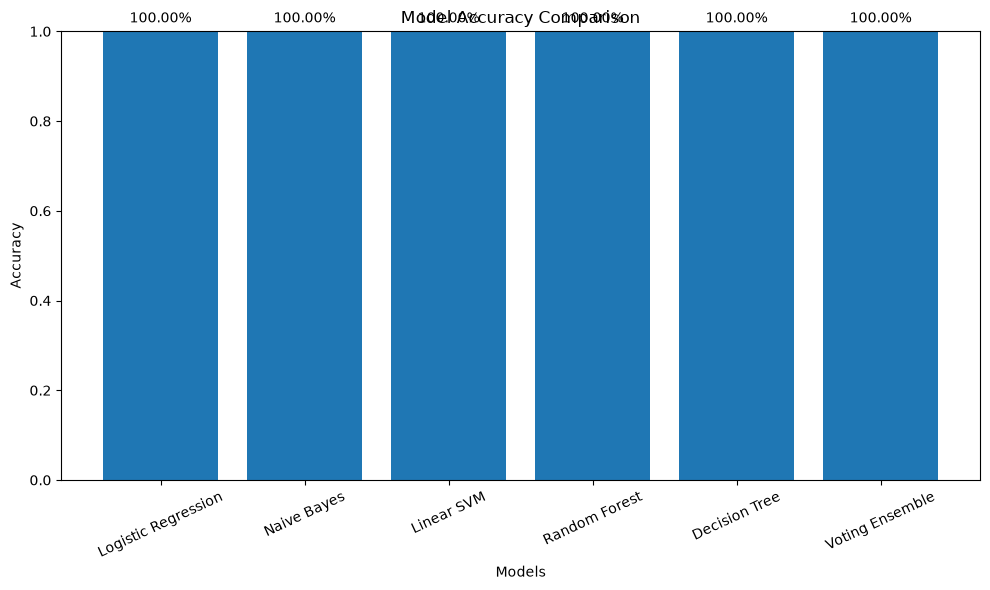

In [32]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from pathlib import Path

# Model predictions
lr_pred = lr.predict(X_test_tfidf)
nb_pred = nb.predict(X_test_tfidf)
svm_pred = svm.predict(X_test_tfidf)
rf_pred = rf.predict(X_test_tfidf)
dt_pred = dt.predict(X_test_tfidf)

# Voting Ensemble prediction
voting_pred = voting_model.predict(X_test_tfidf)

# Model names
model_names = [
    "Logistic Regression",
    "Naive Bayes",
    "Linear SVM",
    "Random Forest",
    "Decision Tree",
    "Voting Ensemble"
]

# Accuracy scores
accuracy_scores = [
    accuracy_score(y_test, lr_pred),
    accuracy_score(y_test, nb_pred),
    accuracy_score(y_test, svm_pred),
    accuracy_score(y_test, rf_pred),
    accuracy_score(y_test, dt_pred),
    accuracy_score(y_test, voting_pred)
]

# Create results folder
results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

# Plot
plt.figure(figsize=(10, 6))

plt.bar(
    model_names,
    accuracy_scores
)

plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")
plt.xticks(rotation=25)
plt.ylim(0, 1)

# Display accuracy values
for i, score in enumerate(accuracy_scores):
    plt.text(
        i,
        score + 0.02,
        f"{score:.2%}",
        ha="center"
    )

plt.tight_layout()

# Save image
plt.savefig(
    "../results/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

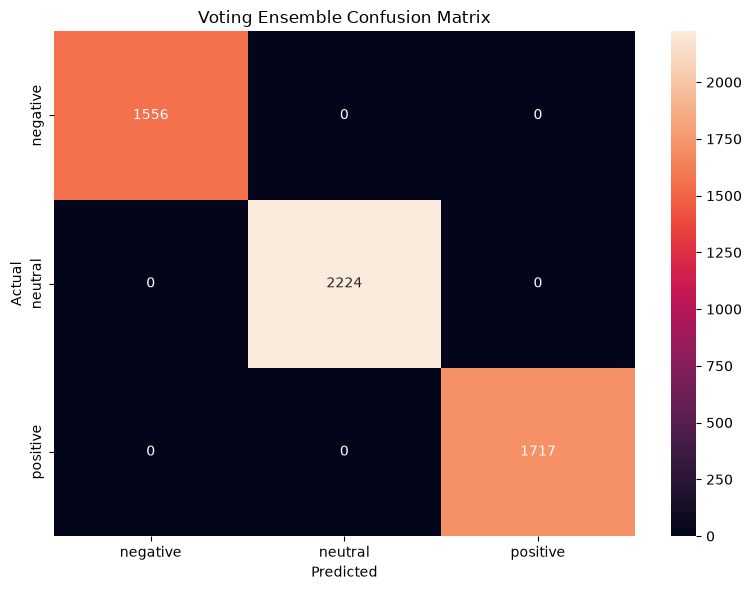

In [33]:
labels = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    ensemble_pred,
    labels=labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Voting Ensemble Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "../results/confusion_matrix.png",
    dpi=300
)

plt.show()

In [34]:
model_package = {
    "tfidf": tfidf,
    "logistic_regression": lr,
    "naive_bayes": nb,
    "linear_svm": svm,
    "random_forest": rf,
    "decision_tree": dt,
    "voting_ensemble": voting_model
}

In [35]:
joblib.dump(
    model_package,
    "../models/sentiment_model.pkl"
)

print(
    "Model saved successfully!"
)

Model saved successfully!
